# Эффективность рекламных каналов: август–сентябрь 2026

Тестовое задание. <br>
Данный ноутбук не является продакшен версией и служит для демонстрации расчётов и анализа. <br>
Затраченое время: *2ч* <br>
Вопрос: какой канал эффективнее по расходам, заявкам, оплаченным сделкам и поступлениям?

Данные — три учебные выгрузки: `01_ad_costs.csv`, `02_crm.csv`, `03_payments.csv`. <br>

Главный вывод: дешёвый трафик (VK) не лучший по конверсии, Yandex — лучший по оплатам, Telegram — лучший по окупаемости<br> Деньги отстают от заявок на месяц-два.

Запуск: <br>
Способ №1. Нажать `Run all` сверху на панели. Ноутбук автоматически попросит дать доступ к Colab и скачает все три таблицы из ссылки google disk, что вы мне направили. <br>
Способ №2. Нажать слева на знак папки `Files` и положить вручную три таблицы в папку `/content`, перетаскивая их курсором мыши или при помощи наатия на `Upload to session storage`. После чего нажать `Run all` сверху на панели.

## 1. Данные: загрузка и диагностика

Файлы — сырые выгрузки (UTF-8 с BOM, разделитель `;`), а не очищенные таблицы. Сначала выясняем, что с ними не так, чтобы зафиксировать правила учёта.

Импорты, константы (срез, месяцы отчёта) и настройка отображения.

In [35]:
import io
import shutil
import tempfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

# Настройка отображение в ноутбуке
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", 50)

# Установка глобальных переменных
CUTOFF = pd.Timestamp("2026-10-21 23:59:59")
REPORT_MONTHS = ["2026-08", "2026-09"]
PAID_CHANNELS = ["yandex", "vk", "telegram"]
ORGANIC = "organic/без источника"
MONTH_RU = {"2026-07": "июль", "2026-08": "август", "2026-09": "сентябрь", "2026-10": "октябрь"}

Стиль графиков

In [36]:
sns.set_theme(style="whitegrid", context="notebook", palette="tab10")
mpl.rcParams.update({
    "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 150,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#d9d9d9",
    "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False,
})
CAT = sns.color_palette("tab10")
MUTED = "#b8b8b8"

Косметические функции для ноутбука

In [37]:
def show_df_summary(df):
  # Перехватываем вывод info в буфер
  buf = io.StringIO()
  df.info(buf=buf)
  info_str = buf.getvalue()

  # Создаем HTML-контейнер с flexbox для размещения рядом
  html_output = f"""
    <div style="display: flex; gap: 20px; align-items: flex-start;">
        <div style="flex: 1;">
            <h4 style="margin-top: 0;">df.info()</h4>
            <pre style="background: #f8f9fa; color: #333; padding: 10px; border-radius: 5px; font-size: 12px; white-space: pre-wrap; font-family: monospace;">{info_str}</pre>
        </div>
        <div style="flex: 1;">
            <h4 style="margin-top: 0;">df.describe()</h4>
            {df.describe(include='all').to_html()}
        </div>
    </div>
    """
  display(HTML(html_output))

def display_side_by_side(df1, df2, title1='Таблица 1', title2='Таблица 2'):
  html = f"""
    <div style="display: flex; gap: 20px;">
        <div style="flex: 1;"><h4>{title1}</h4>{df1._repr_html_()}</div>
        <div style="flex: 1;"><h4>{title2}</h4>{df2._repr_html_()}</div>
    </div>
    """
  display(HTML(html))

Находим каталог с данными (локально или `/content` для Colab) и читаем три файла.

In [38]:
FILES = ("01_ad_costs.csv", "02_crm.csv", "03_payments.csv")
DRIVE_ID = "EXAMPLE124xdwd123" # Вставить сюда токен ссылки на Google Disk 

def find_data_dir():
    for c in [Path.cwd(), Path("/content"), *Path.cwd().parents]:
        if all((c / f).exists() for f in FILES):
            return c
    from google.colab import auth
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload
    auth.authenticate_user()
    drive = build("drive", "v3", cache_discovery=False)
    items = drive.files().list(q=f"'{DRIVE_ID}' in parents and trashed = false",
                               fields="files(id,name)", supportsAllDrives=True).execute()["files"]
    dest = Path("/content")
    for it in items:
        if it["name"] in FILES:
            with open(dest / it["name"], "wb") as fh:
                dl = MediaIoBaseDownload(fh, drive.files().get_media(fileId=it["id"]))
                while not dl.next_chunk()[1]:
                    pass
    return dest

DATA_DIR = find_data_dir()
read_csv = lambda p: pd.read_csv(p, sep=";", encoding="utf-8-sig")
costs_raw, crm_raw, pay_raw = (read_csv(DATA_DIR / f) for f in FILES)
print("Данные:", DATA_DIR)
print("ad_costs:", costs_raw.shape, "| crm:", crm_raw.shape, "| payments:", pay_raw.shape)

Данные: /content
ad_costs: (374, 7) | crm: (2700, 9) | payments: (888, 5)


Видим: расходы — 374 строки, CRM — 2 700 строк (это снапшоты), платежи — 888 операций. Переходим к точечной диагностике каждого файла.

### Раскрытие данных, быстрый EDA

In [39]:
costs_raw.head()

,date,campaign_id,channel,campaign_name,impressions,clicks,cost_rub
0,2026-08-15,YD102,yandex,design_search,1722,82,3396.40
1,2026-09-16,TG301,telegram,python_channels,2880,72,1926.40
2,2026-08-15,TG301,telegram,python_channels,1645,35,1727.17
3,2026-08-02,TG301,telegram,python_channels,1224,34,1484.43
4,2026-09-29,YD101,yandex,python_search,3596,116,3642.10


In [40]:
show_df_summary(costs_raw)

,date,campaign_id,channel,campaign_name,impressions,clicks,cost_rub
count,374,374,374,374,374.000000,374.000000,374.000000
unique,61,6,3,6,NaN,NaN,NaN
top,2026-09-13,VK202,yandex,design_feed,NaN,NaN,NaN
freq,7,63,125,63,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,2397.994652,63.754011,2309.429064
std,NaN,NaN,NaN,NaN,1405.376886,32.260724,791.819722
min,NaN,NaN,NaN,NaN,480.000000,20.000000,1169.240000
25%,NaN,NaN,NaN,NaN,1408.500000,41.000000,1636.482500
50%,NaN,NaN,NaN,NaN,2011.500000,55.500000,2142.835000
75%,NaN,NaN,NaN,NaN,2943.750000,79.750000,2902.650000


In [41]:
crm_raw.head()

,deal_id,contact_id,created_at,updated_at,campaign_id,utm_source,utm_campaign,program,status
0,D00481,C00481,2026-08-20 16:10:00,2026-08-30 16:10:00,VK201,vk,python_feed,Python,new
1,D02218,C01153,2026-09-04 14:23:00,2026-09-15 14:23:00,VK201,vk,python_feed,Python,lost
2,D02352,C02352,2026-09-07 15:37:00,2026-09-11 15:37:00,VK201,vk,python-feed,Python,in_progress
3,D01339,C01339,2026-09-10 11:23:00,2026-09-12 11:23:00,VK201,vk,python_feed,Python,lost
4,D01399,C01399,2026-09-05 15:58:00,2026-09-07 15:58:00,VK202,VK,DESIGN-FEED,Дизайн,in_progress


In [42]:
show_df_summary(crm_raw)

columns = ["campaign_id", "utm_source", "utm_campaign", "program", "status"]

df_summary = pd.DataFrame({
    "column_name": columns,
    "unique_values": [
        ", ".join(str(x) for x in crm_raw[col].unique()) for col in columns
    ],
})

df_summary

,deal_id,contact_id,created_at,updated_at,campaign_id,utm_source,utm_campaign,program,status
count,2700,2700,2700,2700,2234,2663,2409,2700,2700
unique,2600,2248,2542,2608,6,8,24,2,4
top,D00044,C00044,2026-07-26 17:13:00,2026-08-21 14:44:00,VK201,vk,python_feed,Python,won
freq,3,8,3,3,543,855,440,1520,719


,column_name,unique_values
0,campaign_id,"VK201, VK202, TG302, YD101, nan, YD102, TG301"
1,utm_source,"vk, VK , telegram, YANDEX , organic, yandex, nan, TELEGRAM , other"
2,utm_campaign,"python_feed, python-feed, DESIGN-FEED , design-channels, PYTHON_SEARCH , nan, python_search, design_search, DESIGN_SEARCH , DESIGN_FEED , python_channels, design_channels, PYTHON-SEARCH , PYTHON_FEED , design_feed, design-search, python-channels, DESIGN-SEARCH , PYTHON_CHANNELS , design-feed, PYTHON-FEED , DESIGN_CHANNELS , python-search, PYTHON-CHANNELS , DESIGN-CHANNELS"
3,program,"Python, Дизайн"
4,status,"new, lost, in_progress, won"


In [43]:
pay_raw.head()

,payment_id,deal_id,payment_date,operation,amount_rub
0,P00809,D02442,2026-10-03 19:54:00,payment,15000.0
1,P00521,D01402,2026-10-07 21:52:00,payment,40000.0
2,P00092,D00163,2026-09-17 18:38:00,payment,80000.0
3,P00148,D00302,2026-08-30 16:24:00,payment,30000.0
4,P00501,D01295,2026-10-17 10:02:00,payment,45000.0


In [44]:
show_df_summary(pay_raw)
print("Уникальные значения operation:", *pay_raw["operation"].unique())

,payment_id,deal_id,payment_date,operation,amount_rub
count,888,888,888,888,888.000000
unique,870,661,864,2,NaN
top,P00620,D02436,2026-10-12 18:25:00,payment,NaN
freq,2,3,2,837,NaN
mean,NaN,NaN,NaN,NaN,40621.903153
std,NaN,NaN,NaN,NaN,20514.942625
min,NaN,NaN,NaN,NaN,7500.000000
25%,NaN,NaN,NaN,NaN,22500.000000
50%,NaN,NaN,NaN,NaN,40000.000000
75%,NaN,NaN,NaN,NaN,60000.000000


Уникальные значения operation: payment refund


### Расходы
Дубли строк, конфликты ключа `date+campaign_id`, покрытие дней и соответствие кампаний каналам.

In [45]:
def diag_costs(c):
    c = c.copy(); c["date"] = pd.to_datetime(c["date"], errors="coerce")
    conflicts = int(c.drop_duplicates().duplicated(["date", "campaign_id"], keep=False).sum())
    multi = int((c.groupby("campaign_id")["channel"].nunique() > 1).sum())
    return pd.DataFrame([
        ("строк / полных дублей", f"{len(c)} / {int(c.duplicated().sum())}"),
        ("конфликты date+campaign_id", conflicts),
        ("дней покрыто", f"{c['date'].dt.date.nunique()}/61"),
        ("кампаний / канал-конфликтов", f"{c['campaign_id'].nunique()} / {multi}"),
    ], columns=["Наблюдение", "Значение"])

diag_costs(costs_raw)

,Наблюдение,Значение
0,строк / полных дублей,374 / 8
1,конфликты date+campaign_id,0
2,дней покрыто,61/61
3,кампаний / канал-конфликтов,6 / 0


8 полных дублей строк, конфликтов по ключу нет, покрыты все 61 день<br>
6 кампаний соответствуют одному каналу — расходы чистим только от дублей.

### CRM
Cколько уникальных сделок, снапшотов и насколько грязные utm-поля.

In [46]:
def diag_crm(d):
    d = d.copy()
    d["created_at"] = pd.to_datetime(d["created_at"], errors="coerce")
    src = d["utm_source"].dropna()
    return pd.DataFrame([
        ("строк / уникальных deal_id", f"{len(d)} / {d['deal_id'].nunique()}"),
        ("сделок с несколькими снапшотами", int(d["deal_id"].duplicated().sum())),
        ("utm_source с регистром/пробелами", int((src != src.str.strip().str.lower()).sum())),
        ("сделок без campaign_id", int(d["campaign_id"].isna().sum())),
        ("июльских сделок (ранняя когорта)", int((d["created_at"] < pd.Timestamp("2026-08-01")).sum())),
    ], columns=["Наблюдение", "Значение"])

diag_crm(crm_raw)

,Наблюдение,Значение
0,строк / уникальных deal_id,2700 / 2600
1,сделок с несколькими снапшотами,100
2,utm_source с регистром/пробелами,360
3,сделок без campaign_id,466
4,июльских сделок (ранняя когорта),165


2 700 строк это 2 600 уникальных сделок: 99 сделок имеют по 2–3 снапшота. <br>`utm_source` грязный (регистр/пробелы), у 466 сделок нет `campaign_id`.

### Платежи
Дубли операций, возвраты и операции без сделки в CRM.

In [47]:
def diag_pay(p, crm_raw):
    p = p.copy()
    ref = p[p["operation"] == "refund"]
    return pd.DataFrame([
        ("строк / дублей payment_id", f"{len(p)} / {int(p['payment_id'].duplicated().sum())}"),
        ("возвратов (строк / сумма)", f"{len(ref)} / {ref['amount_rub'].sum():,.0f} ₽".replace(",", " ")),
        ("платежей с deal_id вне CRM", int((~p["deal_id"].isin(crm_raw["deal_id"])).sum())),
    ], columns=["Наблюдение", "Значение"])

diag_pay(pay_raw, crm_raw)

,Наблюдение,Значение
0,строк / дублей payment_id,888 / 18
1,возвратов (строк / сумма),51 / 1 171 250 ₽
2,платежей с deal_id вне CRM,7


18 дублей `payment_id`, <br>51 возврат на 1 171 250 ₽, <br>7 операций ссылаются на сделки вне CRM — их учтём в контроле полноты.

### Проблемы, найденные в данных, и принятые решения

| # | Проблема | Решение |
|---|---|---|
| 1 | ad_costs: полные дубли строк (день+кампания) | дедуп по ключу `date + campaign_id` |
| 2 | crm: один `deal_id` = 2–3 снапшота с разными `status` | оставляем снапшот с максимальным `updated_at` |
| 3 | `utm_source` грязный: регистр, пробелы | нормализация `strip().lower()`<br> `utm_campaign` как ключ не используем |
| 4 | `campaign_id` пуст у 466 сделок | атрибуция: `campaign_id → канал`<br> фолбэк — нормализованный `utm_source`<br> остальное — корзина "organic/без источника" |
| 5 | payments: дубли `payment_id` | дедуп по `payment_id` |
| 6 | 7 платежей с `deal_id` вне CRM (`D_EXT*`) | в каналы не входят, показываем в контроле полноты |
| 7 | `status=won` ≠ деньги | «оплаченная сделка» — по платежам (net > 0)<br> статус CRM — отдельно |
| 8 | refund хранится с положительной суммой | знак по операции: payment +, refund −<br> по сделке считаем net |

## 2. Правила учёта

1. **Дедуп:** расходы — по `date+campaign_id`;<br> CRM — по `deal_id` (снапшот с макс. `updated_at`);<br> платежи — по `payment_id`.
2. **Канал:** `campaign_id → channel` из расходов;<br> фолбэк — нормализованный `utm_source` (vk/yandex/telegram);<br> остальное в "organic/без источника".
4. **Месяц:** заявки — по `created_at` сделки;<br> "касса" по `payment_date`;<br>  поступления когорты это все платежи сделок месяца (вкл. октябрь до среза) для честного ROMI.
5. **Оплаченная сделка:** ≥1 операция `payment` и net > 0 (net = платежи − возвраты).
6. **Срез:** 21.10.2026 23:59:59; позже среза — отсекается (в выгрузке такого нет).

## 3. Подготовка данных
Конвейер из пяти шагов:
- чистим каждый файл
- назначаем канал
- считаем деньги по сделкам
- собираем таблицу канал×месяц
- метрики
<br>
Функции переиспользуются смоук-тестом (раздел 9).

Расходы: парсим дату и числа, убираем дубли по `date+campaign_id`, добавляем месяц.

In [48]:
def clean_costs(raw):
    df = raw.copy()
    # Приводим к типу времени
    df["date"] = pd.to_datetime(df["date"])
    # Приводи к численому типу
    for col in ["impressions", "clicks", "cost_rub"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    # Убераем дубли
    df = df.drop_duplicates(subset=["date", "campaign_id"], keep="first")
    # Преобразование в новый столбец для удобного вида
    df["month"] = df["date"].dt.to_period("M").astype(str)
    return df, len(raw) - len(df)

costs, dup_c = clean_costs(costs_raw)
print("Удалённые дубли:", dup_c)
costs.head()

Удалённые дубли: 8


,date,campaign_id,channel,campaign_name,impressions,clicks,cost_rub,month
0,2026-08-15,YD102,yandex,design_search,1722,82,3396.40,2026-08
1,2026-09-16,TG301,telegram,python_channels,2880,72,1926.40,2026-09
2,2026-08-15,TG301,telegram,python_channels,1645,35,1727.17,2026-08
3,2026-08-02,TG301,telegram,python_channels,1224,34,1484.43,2026-08
4,2026-09-29,YD101,yandex,python_search,3596,116,3642.10,2026-09


CRM: парсим даты, на каждый `deal_id` оставляем снапшот с максимальным `updated_at`, нормализуем `utm_source`.

In [49]:
def clean_crm(raw):
    df = raw.copy()
    # Приводим к типу времени
    df["created_at"] = pd.to_datetime(df["created_at"])
    df["updated_at"] = pd.to_datetime(df["updated_at"])
    # Сортировка и удаление дубликаов
    df = df.sort_values(["deal_id", "updated_at"]).drop_duplicates("deal_id", keep="last")
    # Преобразование в новый столбец для удобного вида
    df["month"] = df["created_at"].dt.to_period("M").astype(str)
    # Нормализация для исправления регистра
    df["utm_source_n"] = df["utm_source"].str.strip().str.lower()
    return df, len(raw) - len(df)

crm, dup_d = clean_crm(crm_raw)
print("Удалённые дубли:", dup_d)
crm.head()

Удалённые дубли: 100


,deal_id,contact_id,created_at,updated_at,campaign_id,utm_source,utm_campaign,program,status,month,utm_source_n
977,D00001,C00001,2026-07-21 19:06:00,2026-07-22 19:06:00,TG302,telegram,design_channels,Дизайн,lost,2026-07,telegram
1028,D00002,C00002,2026-07-11 16:13:00,2026-07-12 16:13:00,YD101,yandex,python-search,Python,in_progress,2026-07,yandex
620,D00003,C00003,2026-07-03 14:37:00,2026-07-09 14:37:00,YD101,YANDEX,PYTHON_SEARCH,Python,lost,2026-07,yandex
2332,D00004,C00004,2026-07-29 19:45:00,2026-08-05 19:45:00,TG301,telegram,python_channels,Python,lost,2026-07,telegram
77,D00005,C00004,2026-07-26 08:40:00,2026-08-21 08:40:00,VK201,vk,python_feed,Python,won,2026-07,vk


Платежи: парсим даты, убираем дубли `payment_id`, знак по операции (refund — минус), считаем net по строке.

In [50]:
def clean_payments(raw):
    df = raw.copy()
    # Преобразуем по типу времени
    df["payment_date"] = pd.to_datetime(df["payment_date"])
    # Приводим в числовой формат
    df["amount_rub"] = pd.to_numeric(df["amount_rub"], errors="coerce")
    # Нормализуем для исправления регистра
    df["operation"] = df["operation"].str.strip().str.lower()
    # Убираем дубликаты
    df = df.drop_duplicates("payment_id", keep="first")
    # Присваиваем новый столбец для определения числового смысла к operation
    df["sign"] = np.where(df["operation"] == "refund", -1, 1)
    # Создаём новый столбец с суммой операции, которые входят в множество вещественных чисел
    df["net_rub"] = df["sign"] * df["amount_rub"]
    # Преобразование в новый столбец для удобного вида
    df["month"] = df["payment_date"].dt.to_period("M").astype(str)
    return df, len(raw) - len(df)

pay, dup_p = clean_payments(pay_raw)
print("Удалённые дубли:", dup_p)
pay.head()

Удалённые дубли: 18


,payment_id,deal_id,payment_date,operation,amount_rub,sign,net_rub,month
0,P00809,D02442,2026-10-03 19:54:00,payment,15000.0,1,15000.0,2026-10
1,P00521,D01402,2026-10-07 21:52:00,payment,40000.0,1,40000.0,2026-10
2,P00092,D00163,2026-09-17 18:38:00,payment,80000.0,1,80000.0,2026-09
3,P00148,D00302,2026-08-30 16:24:00,payment,30000.0,1,30000.0,2026-08
4,P00501,D01295,2026-10-17 10:02:00,payment,45000.0,1,45000.0,2026-10


Канал сделки:
- Приоритет `campaign_id` из справочника расходов
- Фолбэк — нормализованный `utm_source`
- Остальное — корзина «organic/без источника».

In [51]:
def attribute_channels(crm, costs):
    # Устанавливаем правило для маппинга: дедуп и индексация
    camp2ch = costs.drop_duplicates("campaign_id").set_index("campaign_id")["channel"]
    # Маппинг для фолбэка для заполнения пустых значений
    utm = crm["utm_source_n"].where(crm["utm_source_n"].isin(PAID_CHANNELS))
    crm = crm.copy()
    # Применяем camp2ch & utm
    crm["channel"] = crm["campaign_id"].map(camp2ch).fillna(utm).fillna(ORGANIC)
    return crm

crm = attribute_channels(crm, costs)

**Деньги по сделкам:**
- net = платежи − возвраты;
- "оплаченная сделка" это и есть "платеж" и "net" > 0.
- Платежи-сироты отделяем.

In [52]:
def deal_money(crm, pok):
    # Группировка суммы по id сделки
    net = pok.groupby("deal_id")["net_rub"].sum()
    # Находим все уникальные индентификаторы сделок, для которых тип равен payment
    paid = pok.loc[pok["operation"] == "payment", "deal_id"].unique()
    crm = crm.copy()
    crm["net_rub"] = crm["deal_id"].map(net).fillna(0.0)
    crm["paid_deal"] = crm["deal_id"].isin(paid) & (crm["net_rub"] > 0)
    return crm

known = set(crm["deal_id"])
# Инвертивная верси для оплаты
orphan = pay[~pay["deal_id"].isin(known)]
# Проверяем оплату по сделке. Была? Тогда True
pay_ok = pay[pay["deal_id"].isin(known)]
crm = deal_money(crm, pay_ok)
crm[["net_rub", "paid_deal"]].head(6)

,net_rub,paid_deal
977,0.0,False
1028,0.0,False
620,0.0,False
2332,0.0,False
77,80000.0,True
469,80000.0,True


Связываем платежи с каналом и месяцем сделки (нужно для кассового вида) и определяем агрегацию канал×месяц.

In [53]:
pay_ok = pay_ok.merge(crm[["deal_id", "channel", "month"]]
                      .rename(columns={"month": "deal_month"}), on="deal_id", how="left")

def build_report(crm, pok, costs):
    c = costs[costs["month"].isin(REPORT_MONTHS)]
    d = crm[crm["month"].isin(REPORT_MONTHS)]
    idx = pd.MultiIndex.from_product([PAID_CHANNELS + [ORGANIC], REPORT_MONTHS], names=["channel", "month"])
    rep = pd.DataFrame(index=idx)
    rep["spend_rub"] = c.groupby(["channel", "month"])["cost_rub"].sum()
    rep["leads"] = d.groupby(["channel", "month"])["deal_id"].count()
    rep["paid_deals"] = d[d["paid_deal"]].groupby(["channel", "month"])["deal_id"].count()
    rep["cash_in_rub"] = pok[pok["month"].isin(REPORT_MONTHS)].groupby(["channel", "month"])["net_rub"].sum()
    rep["cohort_net_rub"] = d.groupby(["channel", "month"])["net_rub"].sum()
    return rep.fillna(0).reset_index()


### Метрики эффективности:
**CPL** = расходы/заявки<br>
**CR** = оплаченные/заявки<br>
**ROMI** = (поступления когорты − расходы)/расходы<br>

Три метрики выбраны так, чтобы покрыть воронку целиком и не дублировать друг друга:<br>
CPL — стоимость входа, CR — качество входа, ROMI — деньги на выходе. <br>
По отдельности каждая обманывает: дешёвая заявка может не оплачиваться, высокая конверсия — не окупать дорогой трафик, а "касса месяца" вообще смешивает когорты.<br>
Вместе они дают непротиворечивую картину и позволяют принимать решение о перераспределении бюджета.

In [54]:
def add_metrics(rep):
    rep["cpl_rub"] = np.where(rep["spend_rub"] > 0, rep["spend_rub"] / rep["leads"], np.nan)
    rep["cr_paid_pct"] = np.where(rep["leads"] > 0, 100 * rep["paid_deals"] / rep["leads"], np.nan)
    rep["romi_pct"] = np.where(rep["spend_rub"] > 0, 100 * (rep["cohort_net_rub"] - rep["spend_rub"]) / rep["spend_rub"], np.nan)
    return rep

report = add_metrics(build_report(crm, pay_ok, costs))
report

,channel,month,spend_rub,leads,paid_deals,cash_in_rub,cohort_net_rub,cpl_rub,cr_paid_pct,romi_pct
0,yandex,2026-08,184505.99,370,125,3356250.0,6370000.0,498.664838,33.783784,3352.462438
1,yandex,2026-09,197482.64,383,120,6785000.0,5552500.0,515.620470,31.331593,2711.639545
2,vk,2026-08,107111.65,377,74,2170000.0,3865000.0,284.115782,19.628647,3508.384335
3,vk,2026-09,155877.75,571,62,3368750.0,3218750.0,272.990806,10.858144,1964.919464
4,telegram,2026-08,98063.83,245,60,2110000.0,3260000.0,400.260531,24.489796,3224.365365
5,telegram,2026-09,101509.41,229,64,3340000.0,3172500.0,443.272533,27.947598,3025.326017
6,organic/без источника,2026-08,0.00,108,31,962500.0,1686250.0,NaN,28.703704,NaN
7,organic/без источника,2026-09,0.00,157,55,1926250.0,2438750.0,NaN,35.031847,NaN


Конвейер готов: очистка → атрибуция → деньги → таблица. Дедуп убрал 8 строк расходов, 100 снапшотов CRM и 18 дублей платежей. Переходим к итоговой таблице.

## 4. Итоговая таблица: канал × месяц

Определения: <br>
**Расходы** — `cost_rub` по месяцу даты. <br>
**Заявки** — уникальные сделки месяца. <br>
**Оплаченные** — заявки с net > 0 до среза. <br>
**Касса** — net операций месяца. <br>
**Когорта** — net всех платежей сделок месяца (вкл. октябрь до среза). <br>
**CPL/CR/ROMI** — по формулам выше. <br>
У organic расходы не выгружены → CPL/ROMI пустые. <br>

Читаемая версия: месяцы по-русски, суммы с разделителями тысяч.

In [55]:
def fmt_money(x):
    return f"{x:,.0f}".replace(",", " ") if pd.notna(x) else ""

show = report.copy()
show["month"] = show["month"].map(lambda m: MONTH_RU[m] + " 2026")

for col in ["spend_rub", "cash_in_rub", "cohort_net_rub", "cpl_rub"]:
    show[col] = show[col].map(fmt_money)

show["cr_paid_pct"] = show["cr_paid_pct"].round(1)
show["romi_pct"] = show["romi_pct"].round(0)

display(show.rename(columns={"channel": "Канал", "month": "Месяц",
    "spend_rub": "Расходы, ₽", "leads": "Заявки", "paid_deals": "Оплач.",
    "cash_in_rub": "Касса, ₽", "cohort_net_rub": "Когорта, ₽",
    "cpl_rub": "CPL, ₽", "cr_paid_pct": "CR, %", "romi_pct": "ROMI, %"}))

,Канал,Месяц,"Расходы, ₽",Заявки,Оплач.,"Касса, ₽","Когорта, ₽","CPL, ₽","CR, %","ROMI, %"
0,yandex,август 2026,184 506,370,125,3 356 250,6 370 000,499,33.8,3352.0
1,yandex,сентябрь 2026,197 483,383,120,6 785 000,5 552 500,516,31.3,2712.0
2,vk,август 2026,107 112,377,74,2 170 000,3 865 000,284,19.6,3508.0
3,vk,сентябрь 2026,155 878,571,62,3 368 750,3 218 750,273,10.9,1965.0
4,telegram,август 2026,98 064,245,60,2 110 000,3 260 000,400,24.5,3224.0
5,telegram,сентябрь 2026,101 509,229,64,3 340 000,3 172 500,443,27.9,3025.0
6,organic/без источника,август 2026,0,108,31,962 500,1 686 250,,28.7,NaN
7,organic/без источника,сентябрь 2026,0,157,55,1 926 250,2 438 750,,35.0,NaN


Лидеры за авг+сен:
- расходы — Yandex (381 989 ₽ из 844 551 ₽)
- заявки — VK (948)
- оплаченные — Yandex (245, CR 32,5%)
<br>
Заявка дешевле всех у VK (277 ₽), но конверсия у него ниже всех.<br>
У organic CPL/ROMI пустые.

Сохраняем итоговую таблицу в `output/`

In [56]:
OUT_DIR = DATA_DIR / "output"
OUT_DIR.mkdir(exist_ok=True)
report.to_csv(OUT_DIR / "report_by_channel.csv", index=False, encoding="utf-8-sig")
print("Сохранено:", OUT_DIR / "report_by_channel.csv")

Сохранено: /content/output/report_by_channel.csv


Файл `output/report_by_channel.csv` перезаписывается при каждом запуске — итоги обновляются автоматически.

## 5. Графики

Сравниваем каналы по расходам, деньгам и метрикам, в конце — кассовый лаг.

### Расходы по каналам за август и сентябрь:
У кого бюджет больше и как он меняется.

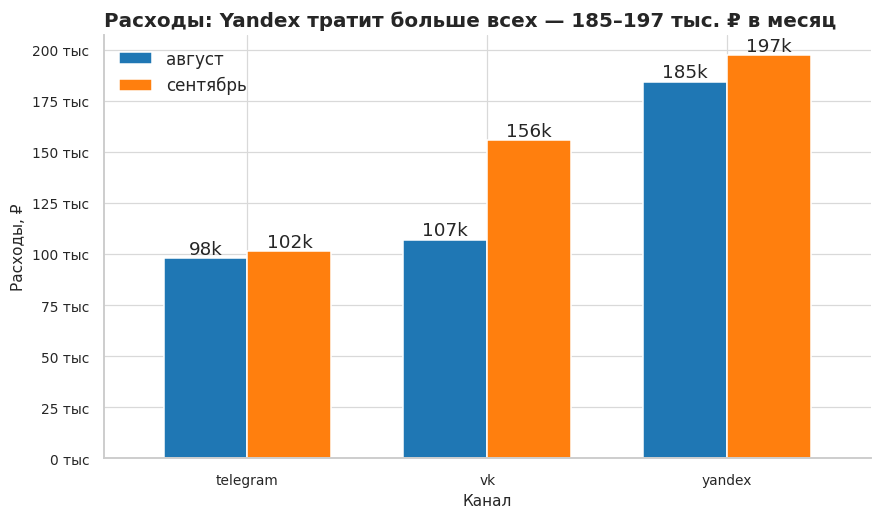

In [57]:
paid_rep = report[report["channel"] != ORGANIC]
piv = paid_rep.pivot_table(index="channel", columns="month", values="spend_rub")[REPORT_MONTHS]
piv.columns = [MONTH_RU[m] for m in piv.columns]
ax = piv.plot.bar(rot=0, width=0.7, color=[CAT[0], CAT[1]], edgecolor="white")
ax.set_title("Расходы: Yandex тратит больше всех — 185–197 тыс. ₽ в месяц")
ax.set_xlabel("Канал")
ax.set_ylabel("Расходы, ₽")
ax.yaxis.set_major_formatter(lambda x, _: f"{x/1000:.0f} тыс")
for cont in ax.containers:
    ax.bar_label(cont, fmt=lambda v: f"{v/1000:.0f}k" if v else "")

Yandex тратит в ~2 раза больше Telegram и в 1,3–1,6 раза больше VK; динамика авг→сен почти плоская.

### Поступления когорт (все платежи сделок месяца)
Кто реально приносит деньги.

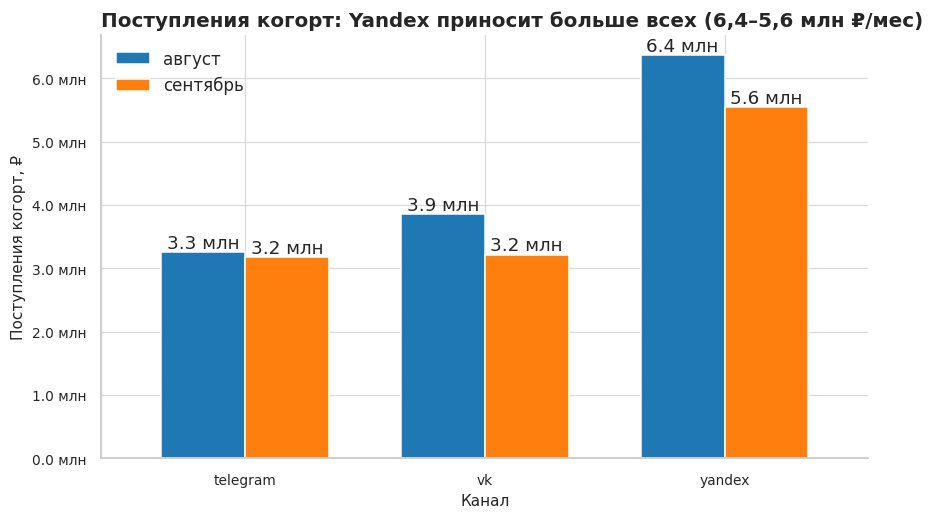

In [58]:
piv = paid_rep.pivot_table(index="channel", columns="month", values="cohort_net_rub")[REPORT_MONTHS]
piv.columns = [MONTH_RU[m] for m in piv.columns]
ax = piv.plot.bar(rot=0, width=0.7, color=[CAT[0], CAT[1]], edgecolor="white")
ax.set_title("Поступления когорт: Yandex приносит больше всех (6,4–5,6 млн ₽/мес)")
ax.set_xlabel("Канал")
ax.set_ylabel("Поступления когорт, ₽")
ax.yaxis.set_major_formatter(lambda x, _: f"{x/1e6:.1f} млн")
for cont in ax.containers:
    ax.bar_label(cont, fmt=lambda v: f"{v/1e6:.1f} млн" if v else "")

Yandex приносит ~2 раза больше Telegram и VK.<br> В сентябре поступления когорт у всех ниже августа.

### CPL — стоимость заявки по каналам.

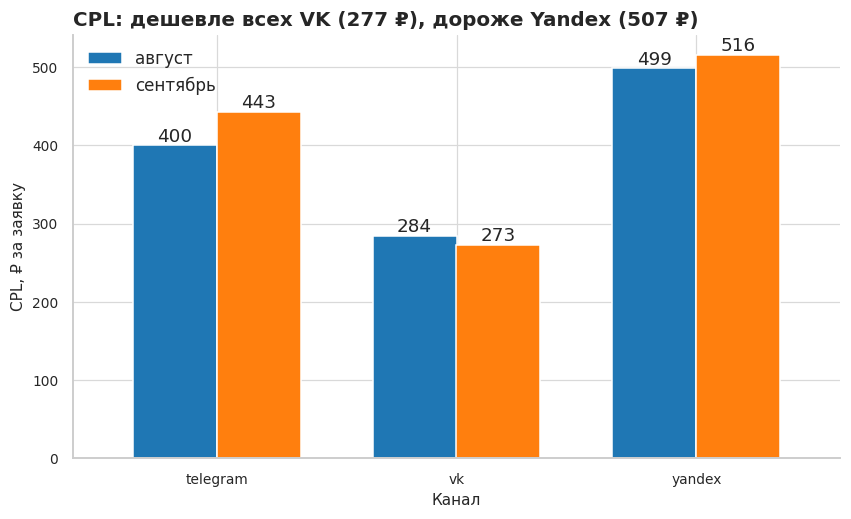

In [59]:
piv = paid_rep.pivot_table(index="channel", columns="month", values="cpl_rub")[REPORT_MONTHS]
piv.columns = [MONTH_RU[m] for m in piv.columns]
ax = piv.plot.bar(rot=0, width=0.7, color=[CAT[0], CAT[1]], edgecolor="white")
ax.set_title("CPL: дешевле всех VK (277 ₽), дороже Yandex (507 ₽)")
ax.set_xlabel("Канал")
ax.set_ylabel("CPL, ₽ за заявку")
for cont in ax.containers:
    ax.bar_label(cont, fmt=lambda v: f"{v:,.0f}".replace(",", " ") if v else "")

VK — дешевле всех (277 ₽ за заявку в среднем за 2 месяца), Yandex — самый дорогой (507 ₽). <br>
Но у Yandex лучшая конверсия (следующий график).

### CR — доля заявок, дошедших до оплаты.

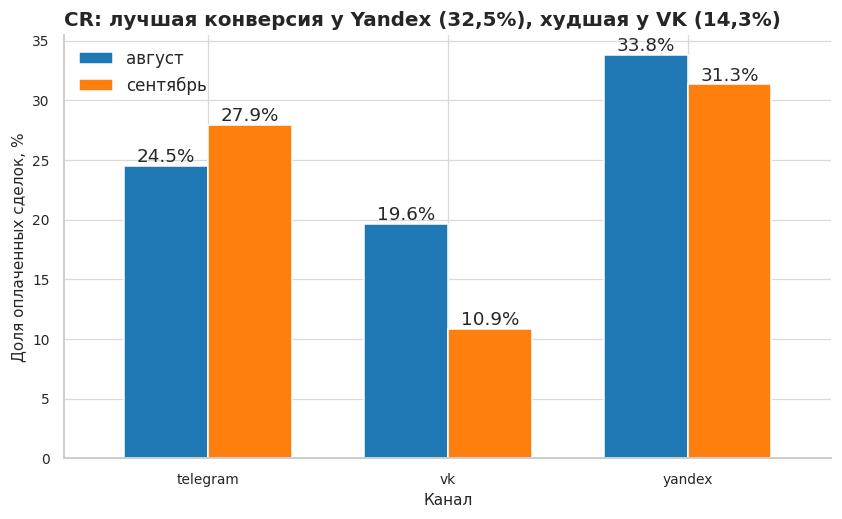

In [60]:
piv = paid_rep.pivot_table(index="channel", columns="month", values="cr_paid_pct")[REPORT_MONTHS]
piv.columns = [MONTH_RU[m] for m in piv.columns]
ax = piv.plot.bar(rot=0, width=0.7, color=[CAT[0], CAT[1]], edgecolor="white")
ax.set_title("CR: лучшая конверсия у Yandex (32,5%), худшая у VK (14,3%)")
ax.set_xlabel("Канал")
ax.set_ylabel("Доля оплаченных сделок, %")
for cont in ax.containers:
    ax.bar_label(cont, fmt=lambda v: f"{v:.1f}%" if v else "")

Конверсия Yandex (32,5%) вдвое выше VK (14,3%). <br>
Дорогой трафик окупается оплатами.

### Кассовый лаг
Из каких когорт заявок пришли поступления каждого месяца.

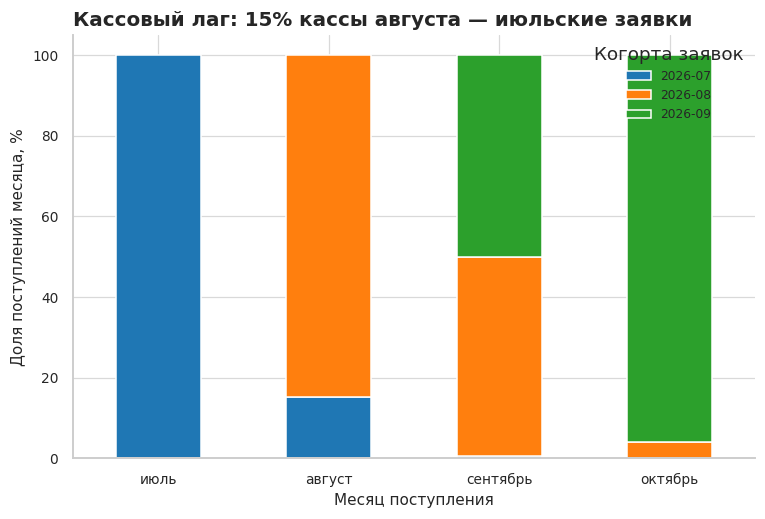

In [61]:
lag = pay_ok.pivot_table(index="month", columns="deal_month", values="net_rub", aggfunc="sum").fillna(0)
lag = lag.reindex([m for m in ["2026-07", "2026-08", "2026-09", "2026-10"] if m in lag.index])
share = lag.div(lag.sum(axis=1), axis=0) * 100
ax = share.plot.bar(stacked=True, rot=0, figsize=(8, 5))
ax.set_xticklabels([MONTH_RU[m] for m in lag.index])
ax.set_xlabel("Месяц поступления")
ax.set_ylabel("Доля поступлений месяца, %")
ax.set_title("Кассовый лаг: 15% кассы августа — июльские заявки")
ax.legend(fontsize=8, title="Когорта заявок");

Август на 15,2% состоит из июльских заявок; октябрьские поступления сентября показывают, что когорта ещё доплачивает — касса месяца смешивает когорты.

## 6. Контроль результата

Проверяем: уникальность ключей после дедупа, сходимость сумм до рубля, полноту объединения и известные расхождения.

Жёсткие проверки: уникальность ключей и сходимость итоговых сумм с исходниками.

In [62]:
checks = []
add_eq = lambda n, e, a: checks.append({"Проверка": n, "Ожидали": e, "Факт": a, "Статус": "PASS" if e == a else "FAIL"})
add_info = lambda n, v: checks.append({"Проверка": n, "Ожидали": "—", "Факт": v, "Статус": "info"})

add_eq("ad_costs: ключ date+campaign_id уникален", len(costs), costs[["date", "campaign_id"]].drop_duplicates().shape[0])
add_eq("ad_costs: конфликтов ключа нет", 0, int(costs_raw.drop_duplicates().duplicated(["date", "campaign_id"], keep=False).sum()))
add_eq("crm: deal_id уникален", len(crm), crm["deal_id"].nunique())
add_eq("payments: payment_id уникален", len(pay), pay["payment_id"].nunique())
add_eq("Расходы отчёта == ad_costs авг+сен", round(report["spend_rub"].sum(), 2), round(costs.loc[costs["month"].isin(REPORT_MONTHS), "cost_rub"].sum(), 2))
add_eq("Заявки отчёта == сделки авг+сен", int(report["leads"].sum()), int(crm["month"].isin(REPORT_MONTHS).sum()))
waterfall = round(orphan["net_rub"].sum() + pay_ok.groupby("month")["net_rub"].sum().sum(), 2)
add_eq("Водопад: платежи = сироты + июль..октябрь", round(pay["net_rub"].sum(), 2), waterfall)
cash_rs = pay_ok[pay_ok["month"].isin(REPORT_MONTHS)]
add_eq("Касса отчёта == net платежей авг+сен", round(report["cash_in_rub"].sum(), 2), round(cash_rs["net_rub"].sum(), 2))

Полнота объединения и известные расхождения (информационно, обработаны правилами учёта).

In [63]:
add_eq("Платежи: покрытие CRM полное", len(pay) - len(orphan), len(pay_ok))
add_info("Платежи, покрытые CRM", f"{len(pay_ok) / len(pay):.1%}")
d = crm[crm["month"].isin(REPORT_MONTHS)]
add_info("Заявки авг+сен с платным каналом", f"{(d['channel'] != ORGANIC).mean():.1%}")
add_info("Сироты-платежи (вне отчёта)", f"{len(orphan)} строк на {orphan['net_rub'].sum():,.0f} ₽".replace(",", " "))
add_info("won без единого платежа (авг+сен)", int(((d["status"] == "won") & ~d["paid_deal"]).sum()))
add_info("не-won, но с деньгами (авг+сен)", int(((d["status"] != "won") & d["paid_deal"]).sum()))
add_info("Сделки с net < 0", int((crm["net_rub"] < 0).sum()))
add_eq("Позже среза данных нет", 0, int((crm["created_at"] > CUTOFF).sum() + (pay_ok["payment_date"] > CUTOFF).sum()))
validation = pd.DataFrame(checks)
OUT_DIR = DATA_DIR / "output"
OUT_DIR.mkdir(exist_ok=True)
validation.to_csv(OUT_DIR / "validation.csv", index=False, encoding="utf-8-sig")
display(validation)

,Проверка,Ожидали,Факт,Статус
0,ad_costs: ключ date+campaign_id уникален,366,366,PASS
1,ad_costs: конфликтов ключа нет,0,0,PASS
2,crm: deal_id уникален,2600,2600,PASS
3,payments: payment_id уникален,870,870,PASS
4,Расходы отчёта == ad_costs авг+сен,844551.27,844551.27,PASS
5,Заявки отчёта == сделки авг+сен,2440,2440,PASS
6,Водопад: платежи = сироты + июль..октябрь,33137250.0,33137250.0,PASS
7,Касса отчёта == net платежей авг+сен,24018750.0,24018750.0,PASS
8,Платежи: покрытие CRM полное,863,863,PASS
9,"Платежи, покрытые CRM",—,99.2%,info


Все жёсткие проверки PASS:
- расходы сходятся до рубля (844 551,27 ₽)
- заявки 2 440, водопад платежей сходится
<br>
Расхождения (сироты, won без денег, органика без расходов) объяснены правилами учёта.

## 7. Выводы

**Вывод 1. Каналы разные по структуре: дешёвый трафик ≠ лучшая конверсия.** <br>
За август–сентябрь (платные каналы): <br>
`CPL` — VK 277 ₽ < Telegram 421 ₽ < Yandex 507 ₽<br>
`CR` в оплату — Yandex 32,5% > Telegram 26,2% > VK 14,3% <br>
`ROMI` по когортам — Telegram +3 123% ≈ Yandex +3 021% > VK +2 594% (данные учебные, `ROMI` завышен).<br>
VK даёт самый дешёвый трафик с худшей конверсией.<br>
Yandex — дорогой, но лучший по оплатам (см. секции 4–5).<br>

**Вывод 2. Деньги отстают от заявок: касса месяца ≠ результат когорты.** <br>
Касса августа — 8 598 750 ₽, из них 1 308 750 ₽ (15,2%) — июльские заявки. <br>
Cентябрьская когорта до среза доплатила в октябре 6 656 250 ₽. <br>
Поэтому `ROMI` сравниваем по "поступлениям когорты", а не по кассе месяца (см. секции 4-5).

**Прочее:** <br>
дедуп убрал 8 строк расходов, 100 снапшотов CRM и 18 дублей платежей (п.1, п.3)<br>
7 платежей-сирот на 126 000 ₽ исключены из каналов и видны в контроле (п.6) <br>
У 55 won-сделок авг+сен нет ни одного платежа — статус и деньги считаем независимо (п.6). Чего утверждать нельзя — раздел 8.

## 8. Ограничения: чего по этим данным утверждать нельзя

1. **Точный ROMI/ДРР по кассе месяца** — деньги отстают от заявок, часть поступлений придёт после среза (см. вывод 2).
2. **Что `status=won` = оплата** — 55 won-сделок авг+сен без единого платежа.<br> Статус ведёт отдел продаж, деньги — отдельная система.
3. **Эффективность органики** — расходы на неё не выгружены.<br> В таблице она только по заявкам и деньгам.
4. **Полнота атрибуции** — 466 сделок без `campaign_id` могли прийти из рекламы.<br> Их заявки и деньги недоучтены в каналах.
5. **Прибыль и выручка** — платежи это движение денег, не начисленная выручка.<br> Себестоимость обучения неизвестна.

## 9. Смоук-тест: обновление отчёта новыми строками

Смоук-тест для проверки работоспособности при добавлении новых данных. Проверяем заранее: копируем данные во временную папку, дописываем строки того же формата — включая **новый `campaign_id` TG900, которого нет в рекламных расходах** (проверка utm-фолбэка) — и перезапускаем конвейер.

Переиспользуемый конвейер: тот же код, что и в основном отчёте.

In [64]:
def run_pipeline(dirp):
    c, _ = clean_costs(read_csv(dirp / "01_ad_costs.csv"))
    d, _ = clean_crm(read_csv(dirp / "02_crm.csv"))
    p, _ = clean_payments(read_csv(dirp / "03_payments.csv"))
    d = attribute_channels(d, c)
    po = p[p["deal_id"].isin(set(d["deal_id"]))]
    d = deal_money(d, po)
    po = po.merge(d[["deal_id", "channel", "month"]]
                  .rename(columns={"month": "deal_month"}), on="deal_id", how="left")
    return add_metrics(build_report(d, po, c))

Добавляемые строки: новая кампания YD999 (2 000 ₽), две сделки — D99999 (YD999) и D99998 (незнакомый TG900, utm ` TELEGRAM `), платёж P99999 на 40 000 ₽.

In [65]:
tmp = Path(tempfile.mkdtemp(prefix="smoke_"))
for f in ["01_ad_costs.csv", "02_crm.csv", "03_payments.csv"]:
    shutil.copy(DATA_DIR / f, tmp / f)

new_cost = pd.DataFrame([{"date": "2026-09-30", "campaign_id": "YD999", "channel": "yandex",
                          "campaign_name": "python_video", "impressions": 1000, "clicks": 50,
                          "cost_rub": 2000.0}])
new_deals = pd.DataFrame([
    {"deal_id": "D99999", "contact_id": "C99999", "created_at": "2026-09-15 12:00:00",
     "updated_at": "2026-09-15 12:00:00", "campaign_id": "YD999", "utm_source": "yandex",
     "utm_campaign": "python_video", "program": "Python", "status": "new"},
    {"deal_id": "D99998", "contact_id": "C99998", "created_at": "2026-09-20 10:00:00",
     "updated_at": "2026-09-20 10:00:00", "campaign_id": "TG900", "utm_source": " TELEGRAM ",
     "utm_campaign": "new_python", "program": "Python", "status": "new"},
])
new_pay = pd.DataFrame([{"payment_id": "P99999", "deal_id": "D99999",
                         "payment_date": "2026-09-20 12:00:00", "operation": "payment",
                         "amount_rub": 40000.0}])

Дописываем строки в копии CSV.

In [66]:
for name, add in [("01_ad_costs.csv", new_cost), ("02_crm.csv", new_deals), ("03_payments.csv", new_pay)]:
    df = read_csv(tmp / name)
    pd.concat([df, add], ignore_index=True).to_csv(tmp / name, sep=";", index=False, encoding="utf-8-sig")

Запускаем конвейер на обновлённых данных и сравниваем дельты с базовым отчётом.

In [67]:
rep2 = run_pipeline(tmp)

def get_cell(rep, ch, month, col):
    return rep.loc[(rep["channel"] == ch) & (rep["month"] == month), col].iloc[0]

cases = [
    ("расходы yandex/сен +2 000 ₽", "yandex", "spend_rub", 2000.0),
    ("заявки yandex/сен +1 (сделка D99999)", "yandex", "leads", 1),
    ("заявки telegram/сен +1 (TG900 → utm)", "telegram", "leads", 1),
    ("оплаченные yandex/сен +1", "yandex", "paid_deals", 1),
    ("касса yandex/сен +40 000 ₽", "yandex", "cash_in_rub", 40000.0),
]
res = []
for name, ch, col, exp in cases:
    actual = float(get_cell(rep2, ch, "2026-09", col) - get_cell(report, ch, "2026-09", col))
    res.append({"Сценарий": name, "Ожидали": exp, "Факт": round(actual, 2),
                "Статус": "PASS" if round(actual, 2) == exp else "FAIL"})

Показываем результат и очищаем временную папку.

In [68]:
display(pd.DataFrame(res))
assert all(r["Статус"] == "PASS" for r in res), "Смоук-тест не пройден"
shutil.rmtree(tmp)

,Сценарий,Ожидали,Факт,Статус
0,расходы yandex/сен +2 000 ₽,2000.0,2000.0,PASS
1,заявки yandex/сен +1 (сделка D99999),1.0,1.0,PASS
2,заявки telegram/сен +1 (TG900 → utm),1.0,1.0,PASS
3,оплаченные yandex/сен +1,1.0,1.0,PASS
4,касса yandex/сен +40 000 ₽,40000.0,40000.0,PASS


Все 5 дельт совпали: новые строки (включая незнакомый `campaign_id` utm-фолбэк) подхватываются автоматически — отчёт обновляется перезапуском.